# Task 1

In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Load shapefile data
districts_fp = "districts/VG1000_KRS.shp"
gdf = gpd.read_file(districts_fp)

### Task 1.a

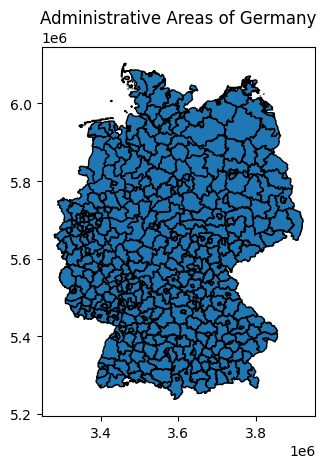

In [3]:
gdf.plot(edgecolor="black")
plt.title("Administrative Areas of Germany")
plt.show()

### Task 1.b

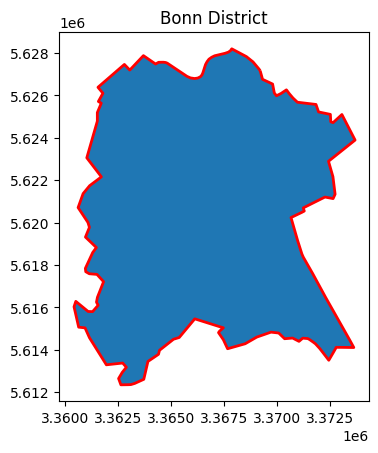

In [4]:
bonn_gdf = gdf[gdf["GEN"] == "Bonn"]
bonn_gdf.plot(edgecolor="red", linewidth=2)
plt.title("Bonn District")
plt.show()

### Task 1.c

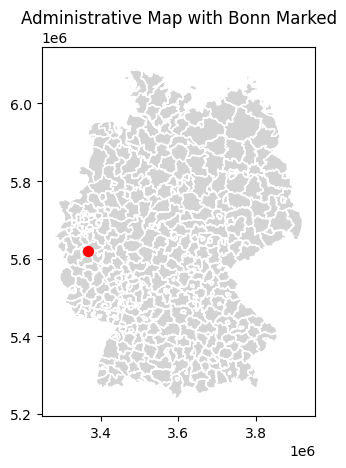

In [5]:
ax = gdf.plot(color='lightgrey', edgecolor='white')
bonn_point = bonn_gdf.geometry.centroid
bonn_point.plot(ax=ax, marker='o', color='red', markersize=50)
plt.title("Administrative Map with Bonn Marked")
plt.show()

### Task 1.d

In [6]:
power_fp = "districts/power_generation.csv"
df_power = pd.read_csv(power_fp)

In [7]:
accum_power = df_power.groupby(['district', 'energyType'])['netRatePower'].sum().reset_index()
accum_power

,district,energyType,netRatePower
0,1001000.0,Natural gas,111453.000
1,1001000.0,Solar radiant energy,12190.985
2,1001000.0,Storage,11.000
3,1001000.0,hard coal,65800.000
4,1001000.0,other gases,769.000
...,...,...,...
3333,16077000.0,heat,20.000
3334,16077000.0,hydro,261.000
3335,16077000.0,other gases,50.000
3336,16077000.0,petroleum products,1720.000


### Task 1.e

In [8]:
wind_power = accum_power[accum_power['energyType'] == 'wind']
wind_power['district'] = pd.to_numeric(wind_power['district'], errors='coerce')
gdf['AGS_0'] = pd.to_numeric(gdf['AGS_0'], errors='coerce')
merged_gdf = gdf.merge(wind_power, how='left', left_on='AGS_0', right_on='district').fillna({'netRatePower': 0})
merged_gdf

<ipython-input-8-069127144232>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wind_power['district'] = pd.to_numeric(wind_power['district'], errors='coerce')


,ADE,GF,BSG,ARS,AGS,SDV_ARS,GEN,BEZ,IBZ,BEM,...,FK_S3,NUTS,ARS_0,AGS_0,WSK,DEBKG_ID,geometry,district,energyType,netRatePower
0,4,4,1,01001,01001,010010000000,Flensburg,Kreisfreie Stadt,40,--,...,R,DEF01,010010000000,1001000,2008-01-01,DEBKGDL1000055UK,"POLYGON ((3527924.046 6075754.73, 3527955.026 ...",1001000.0,wind,69010.0
1,4,4,1,01002,01002,010020000000,Kiel,Kreisfreie Stadt,40,--,...,R,DEF02,010020000000,1002000,2006-01-01,DEBKGDL1000055TK,"POLYGON ((3577255.666 6031939.279, 3577509.282...",NaN,NaN,0.0
2,4,4,1,01003,01003,010030000000,Lübeck,Kreisfreie Stadt,40,--,...,R,DEF03,010030000000,1003000,2006-02-01,DEBKGDL1000055W1,"POLYGON ((3623798.629 5982634.49, 3623806.046 ...",1003000.0,wind,5200.0
3,4,4,1,01004,01004,010040000000,Neumünster,Kreisfreie Stadt,40,--,...,R,DEF04,010040000000,1004000,1970-04-26,DEBKGDL10000560Q,"POLYGON ((3566670.956 6001187.313, 3566515.888...",NaN,NaN,0.0
4,4,4,1,01051,01051,010510044044,Dithmarschen,Kreis,42,--,...,R,DEF05,010510000000,1051000,2011-08-01,DEBKGDL10000563M,"MULTIPOLYGON (((3480619.634 5993137.743, 34806...",1051000.0,wind,2034735.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420,4,2,1,04012,04012,040120000000,Bremerhaven,Kreisfreie Stadt,40,--,...,R,DE502,040120000000,4012000,2010-01-01,DEBKGDL10000561H,"POLYGON ((3471873.518 5934226.127, 3471922.937...",4012000.0,wind,67140.0
421,4,2,1,13003,13003,130030000000,Rostock,Kreisfreie Stadt,40,--,...,R,DE803,130030000000,13003000,2007-01-01,DEBKGDL1000055TM,"POLYGON ((3703953.08 6009743.796, 3704254.374 ...",13003000.0,wind,8525.0
422,4,2,1,13073,13073,130730088088,Vorpommern-Rügen,Landkreis,43,--,...,R,DE80L,130730000000,13073000,2011-09-04,DEBKGDL100007C38,"MULTIPOLYGON (((3722714.216 6032452.373, 37231...",13073000.0,wind,454400.0
423,4,2,1,13074,13074,130740087087,Nordwestmecklenburg,Landkreis,43,--,...,R,DE80M,130740000000,13074000,2011-09-04,DEBKGDL100005C67,"POLYGON ((3648170.858 5985236.89, 3648039.275 ...",13074000.0,wind,256670.0


### Task 1.f

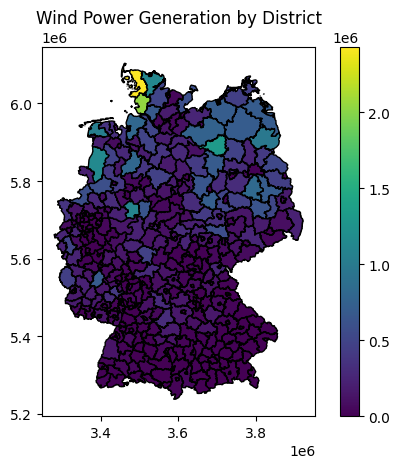

In [9]:
merged_gdf.plot(column='netRatePower', cmap='viridis', legend=True, edgecolor='black')
plt.title("Wind Power Generation by District")
plt.show()

### Task 1.g

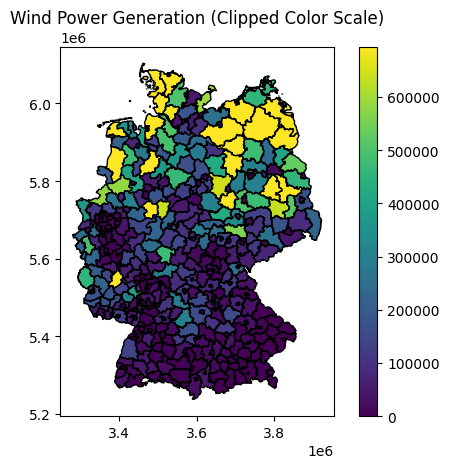

In [10]:
vmax = merged_gdf['netRatePower'].quantile(0.95)
merged_gdf.plot(column='netRatePower', cmap='viridis', legend=True, edgecolor='black', vmax=vmax)
plt.title("Wind Power Generation (Clipped Color Scale)")
plt.show()

# Task 2

### Task 2.a

In [3]:
import dash
from dash import dcc, html, Input, Output, State, MATCH, ALL, ctx
import plotly.express as px
import pandas as pd
import uuid

# Dummy dataset
df = px.data.iris()

# Initialize app
app = dash.Dash(__name__)
app.layout = html.Div([
    html.H2("Scatterplot Explorer"),
    html.Div([
        html.Button("Add New Plot", id='add-plot-btn'),
        html.Button("Delete Selected Plots", id='delete-selected-btn', style={'margin-left': '10px'})
    ], style={'margin-bottom': '20px'}),
    html.Div(id='plots-container')
])

# Helper to create a plot container with unique index
def create_plot(index):
    return html.Div([
        dcc.Graph(
            id={'type': 'dynamic-graph', 'index': index},
            figure=px.scatter(df, x='sepal_width', y='sepal_length', color='species'),
            style={'height': '300px'}
        ),
        html.Div([
            dcc.Checklist(
                options=[{'label': 'Delete', 'value': 'delete'}],
                id={'type': 'delete-check', 'index': index},
                style={'margin-top': '5px'}
            ),
            html.Button("Show Min/Max", id={'type': 'minmax-btn', 'index': index}, style={'margin-left': '10px'}),
            html.Div(id={'type': 'minmax-output', 'index': index}, style={'margin-top': '5px', 'font-size': 'small'})
        ], style={'display': 'flex', 'align-items': 'center', 'gap': '10px'})
    ], style={'border': '1px solid #ccc', 'padding': '10px', 'margin': '10px', 'width': '48%', 'display': 'inline-block', 'vertical-align': 'top'})

# a) Add and Delete Plots
@app.callback(
    Output('plots-container', 'children'),
    Input('add-plot-btn', 'n_clicks'),
    Input('delete-selected-btn', 'n_clicks'),
    State({'type': 'delete-check', 'index': ALL}, 'value'),
    State('plots-container', 'children'),
    prevent_initial_call=True
)
def manage_plots(add_clicks, del_clicks, delete_values, current_children):
    triggered = ctx.triggered_id
    current_children = current_children or []

    if triggered == 'add-plot-btn':
        new_index = str(uuid.uuid4())
        current_children.append(create_plot(new_index))
    elif triggered == 'delete-selected-btn':
        to_delete = [c['props']['children'][0]['props']['id']['index']
                     for c, val in zip(current_children, delete_values) if 'delete' in val]
        current_children = [
            c for c in current_children
            if c['props']['children'][0]['props']['id']['index'] not in to_delete
        ]
    return current_children

# b) Show Min/Max for Each Plot
# Modified plot creation to store x/y axis info as State
def create_plot(index, x_col='sepal_width', y_col='sepal_length'):
    return html.Div([
        dcc.Graph(
            id={'type': 'dynamic-graph', 'index': index},
            figure=px.scatter(df, x=x_col, y=y_col, color='species'),
            style={'height': '300px'}
        ),
        html.Div([
            dcc.Checklist(
                options=[{'label': 'Delete', 'value': 'delete'}],
                id={'type': 'delete-check', 'index': index}
            ),
            html.Button("Show Min/Max", id={'type': 'minmax-btn', 'index': index}),
            dcc.Store(id={'type': 'axis-info', 'index': index}, data={'x': x_col, 'y': y_col}),
            html.Div(id={'type': 'minmax-output', 'index': index})
        ])
    ])

# Updated callback to compute min/max from original df
@app.callback(
    Output({'type': 'minmax-output', 'index': MATCH}, 'children'),
    Input({'type': 'minmax-btn', 'index': MATCH}, 'n_clicks'),
    State({'type': 'axis-info', 'index': MATCH}, 'data'),
    prevent_initial_call=True
)
def show_minmax(n_clicks, axis_data):
    if not axis_data:
        return "Axis info missing."
    x_col = axis_data.get('x')
    y_col = axis_data.get('y')
    if x_col not in df.columns or y_col not in df.columns:
        return "Invalid column names."

    x_vals = df[x_col]
    y_vals = df[y_col]
    return f"X Range: [{x_vals.min():.2f}, {x_vals.max():.2f}], Y Range: [{y_vals.min():.2f}, {y_vals.max():.2f}]"



# c) Brushing & Linking (Selection Sync)
@app.callback(
    Output({'type': 'dynamic-graph', 'index': ALL}, 'figure'),
    Input({'type': 'dynamic-graph', 'index': ALL}, 'selectedData'),
    State({'type': 'dynamic-graph', 'index': ALL}, 'figure')
)
def sync_selection(selected_datas, figures):
    selected_pts = []
    for sel in selected_datas:
        if sel:
            selected_pts = [pt['pointIndex'] for pt in sel['points']]
            break
    new_figs = []
    for fig in figures:
        new_fig = fig.copy()
        for trace in new_fig['data']:
            trace['marker']['color'] = [
                'red' if i in selected_pts else 'lightgray' for i in range(len(trace['x']))
            ]
        new_figs.append(new_fig)
    return new_figs

if __name__ == '__main__':
    app.run(debug=True)


# Task 4

### Task 4.a

A rectilinear grid can be stored as a uniform grid if the spacing between grid points is constant in each dimension. This means that not only are the grid lines aligned with the axes, but the distance between adjacent points in each direction must also be equal and consistent throughout the grid.

### Task 4.b

Yes, curvilinear grids can be used to represent anisotropic voxels. Anisotropic voxels have different sizes along different directions, and curvilinear grids allow for varying distances and orientations between grid points. While the voxels may not remain axis-aligned boxes, the variation in size and shape can still represent anisotropy.